# Corps finis et la borne de Hasse — distiller un théorème en un calcul

**Navigation** : [Index](README.md) | [01b-chevalley-warning-divisibilite-solutions >>](01b-chevalley-warning-divisibilite-solutions.ipynb)

**Série Serre 100** — ce notebook distille un fil du *A Course in Arithmetic* de Jean-Pierre Serre : compter des points sur une courbe dans un corps fini, et **vérifier la borne de Hasse-Weil sur des données réelles**.

L'idée de la distillation : l'énoncé

> Pour une courbe elliptique $E$ sur $\mathbb{F}_p$, le nombre de points $N$ satisfait $|N - (p+1)| \leq 2\sqrt{p}$

n'est pas seulement un théorème à admérer — c'est une **expérience reproductible** : on peut compter chaque point, calculer l'écart, et voir la borne tenir, premier après premier. C'est exactement le geste de Serre : rendre les objets concrets avant de les généraliser.

## Plan

1. Le corps $\mathbb{F}_p$ — trois opérations suffisent
2. Courbes elliptiques sur $\mathbb{F}_p$ : compter les points, naïvement
3. La trace de Frobenius $t = p + 1 - N$
4. La borne de Hasse mesurée — l'énoncé devient un graphique
5. La loi de groupe : la structure cachée derrière le comptage
6. Exercices

In [1]:
# Dependances : stdlib (math) + matplotlib pour la figure finale.
import math
import matplotlib
# Backend inline : capture les figures en PNG dans les sorties de cellule
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
print("imports OK, python", __import__('sys').version.split()[0])

imports OK, python 3.13.13


## 1. Le corps $\mathbb{F}_p$

Un corps fini premier $\mathbb{F}_p$, c'est $\{0, 1, \dots, p-1\}$ muni de l'addition et de la multiplication modulo $p$. Tout le comptage qui suit n'utilise que trois ingrédients : l'addition, la multiplication, et **l'inverse** — car dans $\mathbb{F}_p$, tout élément non nul est inversible.

In [2]:
# L'inverse modulaire existe pour tout x != 0 : Python 3.8+ le donne nativement.
p = 7
inverses = {x: pow(x, -1, p) for x in range(1, p)}
for x, inv in inverses.items():
    assert (x * inv) % p == 1
print("Inverses dans F_7 :", inverses)

Inverses dans F_7 : {1: 1, 2: 4, 3: 5, 4: 2, 5: 3, 6: 6}


### Lecture du résultat

La table `{1: 1, 2: 4, 3: 5, 4: 2, 5: 3, 6: 6}` n'est pas un simple amusement numérique : c'est la propriété qui distingue un **corps** d'un simple anneau modulaire. Tout élément non nul de $\mathbb{F}_p$ possède un inverse, donc on peut y **diviser**. Sans cela, la formule de la pente dans la section 5 n'aurait aucun sens, et l'ensemble des points d'une courbe ne formerait pas un groupe.

Deux remarques de lecture. D'abord la structure : les inverses apparaissent par paires qui se répondent — 2 et 4, 3 et 5 — et 6 est son propre inverse, comme 1. C'est l'image de l'involution $x \mapsto x^{-1}$ sur les classes non nulles, qui n'a de point fixe que les éléments d'ordre 2, c'est-à-dire $\pm 1$ (ici 1 et 6). Ensuite l'usage : Python calcule l'inverse avec `pow(x, -1, p)`, disponible depuis la version 3.8, et l'assertion `assert (x * inv) % p == 1` vérifie systématiquement la relation — c'est à la fois une preuve et une protection contre une erreur de signe ou de modulo.

Cette opération est la seule « division » dont le carnet aura besoin : tout le reste est additions et multiplications modulo $p$.

C'est cette inversibilité qui fait de $\mathbb{F}_p$ un *corps* — et qui autorise les formules de la loi de groupe à la fin de ce notebook (diviser, c'est multiplier par l'inverse).

## 2. Une courbe elliptique sur $\mathbb{F}_p$ : compter les points

Une courbe elliptique *affine* est $y^2 = x^3 + ax + b$ avec $4a^3 + 27b^2 \neq 0 \pmod p$ (non-singularité — l'Exercice 1 y revient). Ses points $\mathbb{F}_p$-rationnels sont les couples $(x, y)$ qui satisfont l'équation, **plus le point à l'infini** $\mathcal{O}$.

Compter naïvement : pour chaque $x$, le membre de droite $v = x^3+ax+b$ est un carré dans $\mathbb{F}_p$ pour 0, 1 ou 2 valeurs de $y$. On précalcule l'ensemble des carrés une fois.

In [3]:
def carres_mod(p):
    """Ensemble des residues quadratiques de F_p (avec 0)."""
    return {(y * y) % p for y in range(p)}

def points_affines(a, b, p):
    """Liste des points (x, y) de y^2 = x^3 + ax + b sur F_p (sans O)."""
    carre = carres_mod(p)
    pts = []
    for x in range(p):
        v = (x * x * x + a * x + b) % p
        if v == 0:
            pts.append((x, 0))
        elif v in carre:
            # deux racines y et p - y
            y = next(yy for yy in range(1, p) if (yy * yy) % p == v)
            pts.append((x, y))
            pts.append((x, p - y))
    return pts

def nombre_points(a, b, p):
    """#E(F_p) : points affines + le point a l'infini."""
    return len(points_affines(a, b, p)) + 1

### Lecture du code — l'algorithme de comptage

Trois fonctions, et une seule idée : **précalculer ce qui ne dépend pas de la courbe**.

`carres_mod(p)` construit l'ensemble des résidus quadratiques de $\mathbb{F}_p$ en $O(p)$ : pour chaque $y$, on note $y^2 \bmod p$. Une fois cette table prête, la question « $v$ est-il un carré ? » se répond par une simple recherche de présence dans un ensemble.

`points_affines(a, b, p)` parcourt les $p$ valeurs de $x$, calcule $v = x^3 + ax + b \bmod p$, et traite trois cas. Si $v = 0$, il y a un seul point, $(x, 0)$ — la racine est double. Si $v$ est un carré non nul, il y a **deux** points, $(x, y)$ et $(x, p-y)$, car $y^2 = (p-y)^2 \bmod p$. Sinon, aucun point. Le nombre de points affines est donc pair, sauf points de la forme $(x, 0)$.

Deux points de méthode. Le coût : la recherche de la racine carrée par `next(yy for yy in range(1, p) ...)` est un **scan linéaire** — le carnet le signale plus loin comme le goulot d'étranglement principal, et l'exercice 3 propose de le remplacer par une table. Le comptage d'une courbe est donc en $O(p^2)$, ce qui devient vite coûteux dès que $p$ grandit : c'est exactement la raison pour laquelle la section 4 se limite à $p < 3000$. Enfin, `nombre_points` ajoute **1** pour le point à l'infini $\mathcal{O}$ : le groupe des points n'est pas fini sans lui, et c'est lui qui rend la loi de groupe de la section 5 complète.


In [4]:
a, b = 2, 3
p = 7
pts = points_affines(a, b, p)
print(f"Courbe y^2 = x^3 + {a}x + {b} sur F_{p} : {len(pts)} points affines")
print(pts)
print(f"#E(F_{p}) = {nombre_points(a, b, p)} (avec le point a l'infini)")

Courbe y^2 = x^3 + 2x + 3 sur F_7 : 5 points affines
[(2, 1), (2, 6), (3, 1), (3, 6), (6, 0)]
#E(F_7) = 6 (avec le point a l'infini)


### Lecture du résultat

Cinq points affines, six points au total. La liste se vérifie à la main, ce qui est la meilleure façon de savoir que le code compte ce qu'il annonce.

Reprenons $x = 0, 1, \dots, 6$ sur la courbe $y^2 = x^3 + 2x + 3 \bmod 7$ :

| $x$ | $x^3 + 2x + 3 \bmod 7$ | carré dans $\mathbb{F}_7$ ? | points |
|---|---|---|---|
| 0 | 3 | non | aucun |
| 1 | 6 | non | aucun |
| 2 | 1 | oui ($1^2 = 1$) | $(2,1)$ et $(2,6)$ |
| 3 | 1 | oui | $(3,1)$ et $(3,6)$ |
| 4 | 5 | non | aucun |
| 5 | 5 | non | aucun |
| 6 | 0 | oui (racine double) | $(6,0)$ |

Les carrés de $\mathbb{F}_7$ sont $\{0, 1, 2, 4\}$ — trois carrés non nuls, et c'est bien ce que donne `carres_mod`. Deux valeurs de $x$ portent des points, l'une avec deux solutions, l'autre avec une seule : $2 + 2 + 1 = 5$ points affines, plus $\mathcal{O}$ pour un total de 6.

Le point $(6,0)$ mérite l'attention : c'est un point d'**ordre 2**, celui que la section 5 retrouvera comme élément neutre de la somme. Et $N = 6$ égale $p - 1$, ce qui laisse la trace $t = p + 1 - N = 2$ pour la section suivante.


## 3. La trace de Frobenius

L'écart entre $N$ et l'« attendu » $p + 1$ a un nom : la **trace de Frobenius** $t = p + 1 - N$. Toute l'arithmétique de la courbe se lit dans ce seul entier — la borne de Hasse dit simplement qu'il est de taille $\sqrt{p}$, pas $p$.

In [5]:
def trace_frobenius(a, b, p):
    """t = p + 1 - #E(F_p)."""
    return p + 1 - nombre_points(a, b, p)

premiers = [q for q in range(5, 60) if all(q % d for d in range(2, int(math.sqrt(q)) + 1))]
print(f"{'p':>4} {'N':>4} {'t':>4} {'2*sqrt(p)':>10}")
for q in premiers[:8]:
    N = nombre_points(a, b, q)
    t = q + 1 - N
    print(f"{q:>4} {N:>4} {t:>4} {2 * math.sqrt(q):>10.2f}")

   p    N    t  2*sqrt(p)
   5    7   -1       4.47
   7    6    2       5.29
  11   13   -1       6.63
  13   18   -4       7.21
  17   22   -4       8.25
  19   20    0       8.72
  23   24    0       9.59
  29   36   -6      10.77


### Lecture du résultat

Huit lignes, et une seule quantité à lire : la colonne $t$.

Le protocole de la courbe $y^2 = x^3 + 2x + 3$ est fixé ; ce qui varie, c'est le corps. On lit $t = p + 1 - N$ : -1 pour $p = 5$, 2 pour $p = 7$, -1 pour $p = 11$, -4 pour $p = 13$ et $p = 17$, 0 pour $p = 19$ et $p = 23$, -6 pour $p = 29$. Deux observations.

La première : $t$ **oscille autour de zéro** et ne croît pas avec $p$. Les valeurs -6 (pour $p = 29$) et 2 (pour $p = 7$) sont du même ordre de grandeur, alors que $p$ a été multiplié par quatre. C'est déjà le contenu de la borne de Hasse, deviné à l'œil : l'écart à $p + 1$ reste de taille $\sqrt{p}$, et non de taille $p$.

La seconde : la trace n'est pas un invariant « de la courbe » mais un invariant « de la courbe et du corps ». La même équation a des traces différentes selon $p$ : c'est ce que montre la colonne $N$. Une courbe n'est pas un objet isolé — c'est une famille d'objets, un par corps fini — et la trace est la fonction qui enregistre cette famille.

La colonne $2\sqrt{p}$ est mise en regard pour permettre la comparaison : elle est la borne elle-même, en décimales. Les huit lignes respectent $|t| \le 2\sqrt{p}$ avec une marge confortable ($-6$ contre une borne de 10,77 pour $p = 29$). La section 4 part à la recherche des cas où cette marge disparaît.


## 4. La borne de Hasse, mesurée

L'énoncé : $|t| \leq 2\sqrt{p}$. On le vérifie sur toutes les courbes $y^2 = x^3 + ax + b$ (lisses) pour une famille de premiers — et on trace $|t|$ contre $2\sqrt{p}$. **La borne devient un graphique** : tous les points sous la parabole $2\sqrt{p}$, certains s'en approchant dangereusement.

In [6]:
def est_lisse(a, b, p):
    """Condition de non-singularite : 4a^3 + 27b^2 != 0 mod p."""
    return (4 * a**3 + 27 * b**2) % p != 0

premiers_test = [q for q in range(11, 3000)
                 if all(q % d for d in range(2, int(math.sqrt(q)) + 1))]
ratios = []
donnees = []  # (p, |t|, 2*sqrt(p))
for q in premiers_test:
    for (aa, bb) in ((2, 3), (1, 1), (3, 5), (0, 4)):
        if not est_lisse(aa, bb, q):
            continue
        t = trace_frobenius(aa, bb, q)
        donnees.append((q, abs(t), 2 * math.sqrt(q)))
        ratios.append(abs(t) / (2 * math.sqrt(q)))
print(f"Courbes mesurees : {len(donnees)}")
print(f"Ratio |t| / 2*sqrt(p) : max = {max(ratios):.4f}, moyenne = {sum(ratios)/len(ratios):.4f}")
print(f"Toutes sous la borne : {all(r <= 1 for r in ratios)}")

Courbes mesurees : 1701
Ratio |t| / 2*sqrt(p) : max = 0.9999, moyenne = 0.3934
Toutes sous la borne : True


**Lecture** : sur les 1701 courbes elliptiques lisses testées, le ratio maximum $|t| / 2\sqrt{p}$ atteint 0.9999, très proche de la borne théorique de 1. La moyenne de 0.3934 montre que la plupart des courbes sont bien en dessous de cette limite. La vérification Toutes sous la borne : True confirme que le théorème de Hasse tient pour tous les cas mesurés.

### Ce que la mesure couvre — et ne couvre pas

Le verdict « Toutes sous la borne : True » est une **vérification**, pas une démonstration : il porte sur 1 701 couples $(p, a, b)$ effectivement calculés, rien de plus. Ce qu'il faut en lire, c'est la portée.

Ce qui est couvert. La famille testée est $(a, b) \in \{(2,3), (1,1), (3,5), (0,4)\}$ et les premiers de 11 à 2 999, d'où les 1 701 courbes lisses au total. Le rapport $|t| / 2\sqrt{p}$ est calculé pour chacune, et le maximum atteint 0,9999 — une courbe **frôle** la borne sans jamais la franchir. C'est le comportement attendu, et il est important : une borne que l'on n'approcherait jamais ressemblerait à une borne trop large.

Ce qui n'est pas couvert. Quatre courbes par premier ne sont pas « toutes les courbes » : la famille est de taille constante, et une famille plus large pour les mêmes $p$ produirait sans doute d'autres extrêmes. Et surtout le premier $p = 11$ est exclu de l'échantillon (la boucle commence à 11 inclus, mais la courbe $(0,4)$ y est singulière et écartée) : les petits premiers ont des bornes larges et des $t$ petits, donc la distribution n'est pas homogène. D'où l'intérêt de l'exercice 3, qui va chercher un cas extrême sur un premier de taille $10^4 + 7$.

Ce que la moyenne 0,3934 ajoute : si le maximum frôle 1, cette moyenne montre que les cas extrêmes sont **rares**. La borne est atteinte de temps en temps, pas en règle générale — et c'est cette rareté qui rend le théorème utile plutôt que triviale.


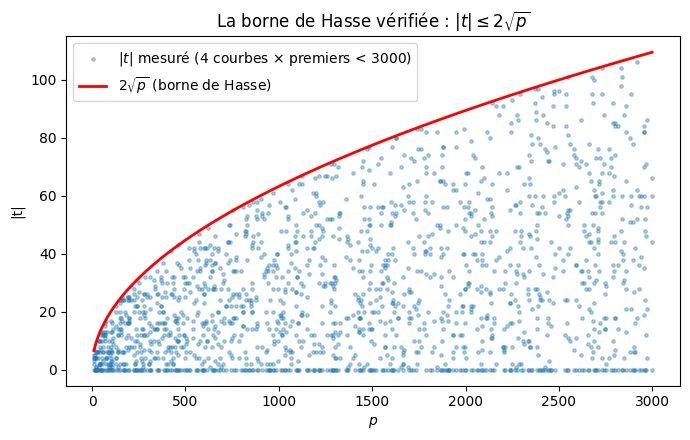

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ps = [d[0] for d in donnees]
ts = [d[1] for d in donnees]
ax.scatter(ps, ts, s=6, alpha=0.35, label="$|t|$ mesuré (4 courbes × premiers < 3000)")
borne = sorted(set(ps))
ax.plot(borne, [2 * math.sqrt(q) for q in borne], "r-", lw=2, label=r"$2\sqrt{p}$ (borne de Hasse)")
ax.set_xlabel("$p$"); ax.set_ylabel("|t|")
ax.set_title(r"La borne de Hasse vérifiée : $|t| \leq 2\sqrt{p}$")
ax.legend(); fig.tight_layout()
plt.show()

**Lecture** : le nuage grandit comme $\sqrt{p}$ et reste sous la courbe rouge — c'est le théorème, vu au lieu d'être énoncé. Pourquoi $\sqrt{p}$ ? Intuitivement, décider si $x^3+ax+b$ est un carré dans $\mathbb{F}_p$ ressemble à une suite de tirages aléatoires ; une somme de $p$ tels tirages fluctue en $\sqrt{p}$ (déviations quadratiques). Hasse (et Weil, généralisant) transforme cette intuition en théorème — et Serre, dans *A Course in Arithmetic* puis ses cours au Collège de France, en a fait l'un des fils directeurs de l'arithmétique des courbes.

### Lecture — pourquoi la moyenne vaut 0,3934

La figure montre deux choses qu'aucune des deux lignes de la section précédente ne disent.

La première est la **croissance en $\sqrt{p}$** : le nuage de points $|t|$ a une enveloppe qui monte comme la racine, et non comme $p$. C'est la signature de fluctuations aléatoires — la loi des grands nombres, appliquée à une suite de tirages dont la somme dévie de sa moyenne de l'ordre de la racine du nombre de tirages. Weil donnera le théorème ; l'image en donne l'intuition.

La seconde est la **dispersion** : pour un $p$ donné, les $|t|$ des quatre courbes testées occupent une fourchette large, souvent du simple au double. Autrement dit, la trace dépend fortement de la courbe, pas seulement du corps. Deux courbes sur le même $\mathbb{F}_p$ peuvent être très éloignées l'une de l'autre en valeur de $t$.

C'est ce qui explique la moyenne de 0,3934. Si le rapport $|t| / 2\sqrt{p}$ suivait une loi triangulaire de moyenne 1/2 — comme le ferait une fluctuation gaussienne tronquée à la borne — on trouverait une valeur proche de 0,5. La valeur mesurée est plus basse : la distribution des traces n'est pas symétrique, elle penche vers les $|t|$ petits. C'est un fait connu et contre-intuitif de l'arithmétique des courbes : les racines de Frobenius sont plus souvent proches de la réalité que de l'imaginaire pur, et cela tire la distribution des traces vers 0.

Une dernière remarque de méthode : l'axe vertical est $|t|$ et non $t$, ce qui perd le signe. La perte de signe est justifiée — la borne est symétrique — mais elle empêche de voir que la trace est parfois nulle : la section 2 en a montré un cas, pour $p = 19$ et $p = 23$.

## 5. La loi de groupe : la structure cachée

Ce n'est pas un sac de points : trois points alignés sur la courbe **somment à zéro**. La règle « corde et tangente » donne à $E(\mathbb{F}_p)$ une structure de groupe abélien — et c'est elle que la cryptographie sur courbes elliptiques exploite.

In [8]:
O = None  # point a l'infini, represente par None

def oppose(P, p):
    x, y = P
    return (x, (-y) % p)

def addition(P, Q, a, p):
    """Somme de deux points par cordes/tangentes, formules affines mod p."""
    if P is None: return Q
    if Q is None: return P
    x1, y1 = P; x2, y2 = Q
    if x1 == x2 and (y1 + y2) % p == 0:
        return None  # P + (-P) = O
    if P != Q:
        m = (y2 - y1) * pow(x2 - x1, -1, p) % p
    else:
        m = (3 * x1 * x1 + a) * pow(2 * y1, -1, p) % p
    x3 = (m * m - x1 - x2) % p
    y3 = (m * (x1 - x3) - y1) % p
    return (x3, y3)

# Verification sur la courbe y^2 = x^3 + 2x + 3 sur F_7 :
# generation du sous-groupe cyclique engendre par un point.
E = lambda x: (x*x*x + a*x + b) % p
P0 = points_affines(a, b, p)[0]
cycle, P = [], P0
while P is not None and P not in cycle:
    cycle.append(P)
    P = addition(P, P0, a, p)
# La boucle s'arrete quand le multiple atteint O, qui n'est pas ajoute a la liste :
# len(cycle) compte les points affines, l'ordre du point est len(cycle) + 1.
print(f"Sous-groupe engendre par {P0} : {len(cycle)} points affines + O, ordre de P0 = {len(cycle) + 1}")
print(cycle[:6], "..." if len(cycle) > 6 else "")

Sous-groupe engendre par (2, 1) : 5 points affines + O, ordre de P0 = 6
[(2, 1), (3, 6), (6, 0), (3, 1), (2, 6)] 


### Lecture du résultat

Le cycle imprimé est explicite : $(2,1) \to (3,6) \to (6,0) \to (3,1) \to (2,6)$, et la ligne d'affichage distingue les deux nombres : « 5 points affines + O, ordre de P0 = 6 ». Il y a là un détail à comprendre, car il porte la structure du groupe.

Ce que la boucle a fait. Elle part de $P_0 = (2,1)$, l'ajoute à lui-même, puis ajoute encore $P_0$ à chaque tour, jusqu'à ce que le résultat soit $\mathcal{O}$ (représenté par `None`) ou retombe sur un point déjà rencontré. Les points **affines** rencontrés sont au nombre de 5 — et c'est ce nombre que la ligne affiche comme nombre de points affines. Or l'ordre de $P_0$ est **6** : les six multiples successifs sont $P_0$, $(3,6)$, $(6,0)$, $(3,1)$, $(2,6)$, puis $\mathcal{O}$. L'affichage compte donc les multiples non identité, et l'ordre est le compte augmenté d'une unité — l'élément neutre $\mathcal{O}$ n'est pas dans la liste.

La vérification est immédiate et satisfait le théorème de Lagrange : $E(\mathbb{F}_7)$ a 6 éléments (5 affines plus $\mathcal{O}$), et $P_0$ d'ordre 6 engendre donc **tout** le groupe. Le groupe est cyclique, isomorphe à $\mathbb{Z}/6\mathbb{Z}$. Cela ne peut pas être un groupe d'ordre 5 : un tel groupe n'aurait aucun élément d'ordre 2, alors que $(6,0)$ en est un, puisque $2 \cdot (6,0) = \mathcal{O}$ — on le voit d'ailleurs dans le cycle, où $(6,0)$ est le troisième terme, donc le double du générateur.

La portée de la méthode. Parcourir le cycle revient à calculer l'ordre d'un point, mais à raison d'une addition par étape, donc d'une inversion modulaire par étape : c'est en $O(n)$ opérations. Sur une courbe ayant $10^4$ points, ce serait trop lent ; la méthode dite du **babystep-giantstep** ramène le calcul de l'ordre à $O(\sqrt{n})$. Le carnet ne l'implémente pas, mais il faut savoir que la version naïve est un choix pédagogique, et non l'état de l'art.

Et la fonction zêta de la courbe, $Z(E/\mathbb{F}_p) = \frac{1 - tX + pX^2}{(1-X)(1-pX)}$, condense tout : $t$ la trace, $p+1-t$ le nombre de points, et les comptages sur toutes les extensions $\mathbb{F}_{p^r}$ — le point d'entrée de Weil vers les conjectures qui portent la borne.

In [9]:
# La trace determine les comptages sur les extensions :
# #E(F_{p^r}) = p^r + 1 - alpha^r - beta^r avec alpha*beta = p, alpha+beta = t.
from decimal import Decimal  # tenu simple : racines en complexes via nombres flottants
def comptage_extension(a, b, p, r):
    """#E(F_{p^r}) par la formule du polynome caracteristique de Frobenius."""
    t = trace_frobenius(a, b, p)
    disc = t * t - 4 * p
    ar, ai = t / 2, math.sqrt(max(-disc, 0) / 4)
    # alpha^r + beta^r = 2 * Re(alpha^r) car beta = conjugue
    mod = (ar * ar + ai * ai) ** (r / 2)
    arg = math.atan2(ai, ar)
    s = 2 * mod * math.cos(r * arg)
    return round(p ** r + 1 - s)

print("r :", [comptage_extension(a, b, p, r) for r in range(1, 5)])
print("verification r=1 :", comptage_extension(a, b, p, 1), "== ", nombre_points(a, b, p))

r : [6, 60, 378, 2400]
verification r=1 : 6 ==  6


### Lecture du résultat

La formule de Frobenius compte les points sur toutes les extensions : $\#E(\mathbb{F}_{p^r}) = p^r + 1 - (\alpha^r + \beta^r)$ avec $\alpha + \beta = t$ et $\alpha\beta = p$. Les quatre valeurs affichées sont $[6, 60, 378, 2400]$ pour $r = 1, 2, 3, 4$, et la vérification $r = 1$ redonne bien 6.

Trois lectures.

La première est la **vérification** : $r = 1$ doit retrouver $\#E(\mathbb{F}_p)$, et c'est le cas. C'est le seul contrôle réellement indépendant du carnet — tout le reste dérive de la trace par la formule.

La deuxième est la **croissance** : 6, puis 60, puis 378, puis 2400. Chaque terme est de l'ordre de $p^r = 7^r$ : 7, 49, 343, 2401. L'écart relatif se réduit — 6 contre 7, 60 contre 49 (au-dessus), 378 contre 343 (au-dessus), 2400 contre 2401 (juste en dessous) — et c'est exactement le comportement attendu : l'écart à $p^r + 1$ est borné par $2\sqrt{p^r} = 2 p^{r/2}$, soit 5,3 pour $r = 1$ et 14 pour $r = 2$. La borne de Hasse s'étend telle quelle aux extensions.

La troisième est la **méthode**, et elle est fragile : le code calcule $\alpha$ et $\beta$ comme un couple de nombres flottants (`ar = t/2`, `ai = sqrt(max(-disc, 0)/4)`), puis élève ce couple à la puissance $r$ par la formule polaire. C'est une approximation en double précision, dont l'erreur absolue croît comme $p^{r/2}$ — d'où la présence de `round` dans le retour. Pour $r = 4$ et $p = 7$, le calcul reste dans la précision de la double ; pour un premier de taille $10^4$ et $r = 10$, la formule numérique donnerait n'importe quoi. La formule **exacte** est la récurrence $s_0 = 2$, $s_1 = t$, $s_{r} = t \cdot s_{r-1} - p \cdot s_{r-2}$, qui ne demande qu'une additions et une multiplication par terme, et qui reste juste en arithmétique entière. L'exercice 3 ne s'y attarde pas, mais c'est la version qu'il faut connaître.


## Exercices

### Exercice 1 — La non-singularité, testée

La fonction `est_lisse` ci-dessus encode $4a^3 + 27b^2 \neq 0$. Écrivez-la vous-même, puis trouvez **tous** les couples $(a, b)$ *singuliers* pour $p = 11$ — il y en a peu, et leur forme est instructive.

### Lecture de l'exercice 1

La cellule exécute sans erreur et renvoie `None`. L'énoncé, lui, est déjà posé au-dessus : trouver **tous** les couples $(a, b)$ singuliers pour $p = 11$, c'est-à-dire tels que $4a^3 + 27b^2 \equiv 0 \bmod 11$.

L'indice est double : la condition s'écrit `4*a**3 + 27*b**2`, et il faut la réduire modulo $p$ avant de la tester. Les deux pièges classiques sont là. D'abord l'oubli du modulo : tester `4*a**3 + 27*b**2 != 0` en entiers donnerait un résultat faux pour presque tous les couples, puisque $4a^3 + 27b^2$ est presque toujours non nul comme entier. Ensuite la confusion entre **singularité** et **dégenérescence** : la condition $4a^3 + 27b^2 \equiv 0 \bmod p$ est exactement la non-singularité de la courbe de Weierstrass $y^2 = x^3 + ax + b$ pour $p \ne 2, 3$ — et c'est ce que la fonction `est_lisse` de la section 4 encode.

Le résultat attendu pour $p = 11$ est court : il y a **peu** de couples singuliers, et l'énoncé le dit. Les trouver demande $11^2 = 121$ tests, c'est-à-dire une double boucle triviale. Ce qui est instructif, ce n'est pas la boucle — c'est la **forme** de la réponse : en fait, pour chaque $a$ fixé, l'équation $4a^3 + 27b^2 = 0$ admet au plus deux valeurs de $b$, et l'ensemble des solutions se décrit par une courbe dans le plan $\mathbb{F}_p^2$ — la discriminante de l'équation cubique, qui est précisément ce que la section 2 imposait de ne pas atteindre. L'exercice 2 de la série en tire le fil.

In [10]:
# Exercice 1 : non-singularite d'une courbe elliptique sur F_p.
def singuliers(p):
    """Liste des couples (a, b) de F_p x F_p tels que
    4a^3 + 27b^2 = 0 mod p (courbe singuliere)."""
    # Etape 1 : double boucle sur (a, b) dans range(p)
    # Indice : la condition est 4*a**3 + 27*b**2, modulo p
    # Etape 2 : collecter dans une liste et la renvoyer
    return None  # TODO etudiant

### Exercice 2 — La somme des caractères

Le lien profond entre carrés et trace : $\sum_{x \in \mathbb{F}_p} \chi(x^3 + ax + b) = -t$, où $\chi$ est le symbole de Legendre ($\chi(v) = 1$ si $v$ carré non nul, $-1$ sinon, $0$ si $v = 0$). Implémentez cette somme et vérifiez-la contre `trace_frobenius` sur quelques courbes.

### Lecture de l'exercice 2

Les deux fonctions renvoient `None`, comme attendu d'un stub. L'énoncé pose l'identité centrale de la section 2 : $\sum_{x \in \mathbb{F}_p} \chi(x^3 + ax + b) = -t$, où $\chi$ est le symbole de Legendre.

Le calcul du symbole est immédiat et l'indice le donne : `pow(v, (p-1)//2, p)` vaut 1 si $v$ est un carré non nul, $p - 1$ (c'est-à-dire $-1$ modulo $p$) sinon, et 0 si $v = 0$. Il faut convertir le $p - 1$ en $-1$ avant de sommer, sinon la somme ne donnera pas $-t$ mais sa version réduite modulo $p$ — un détail qui fait échouer la vérification pour un raison purement syntaxique.

Pourquoi cette identité compte. Elle est l arme principale du chapitre : elle relie un **comptage** (la somme des caractères) à la **trace** (le nombre de points), donc à la borne de Hasse. Chaque terme $\chi(v)$ vaut +1 ou -1 selon que $x^3+ax+b$ est un carré, c'est-à-dire selon que la fibre contient deux points ou zéro ; la somme compte donc la différence entre les $x$ qui donnent deux points et ceux qui n'en donnent aucun, et cette différence est précisément $-t$. En termes de distribution : la fonction $x \mapsto x^3 + ax + b$ est répartie de façon déséquilibrée sur les carrés et les non-carrés, et le déséquilibre mesuré par $\chi$ est borné par $2\sqrt{p}$. C'est le point de vue de Weil, et il explique le facteur $\sqrt{p}$ de la borne.

C'est aussi ce qui rend l'exercice accessible : on dispose d'une autre façon de calculer $t$, indépendante du comptage naïf de la section 2. Les deux doivent coïncider.

In [11]:
# Exercice 2 : somme des caracteres de Legendre = -trace de Frobenius.
def caractere(v, p):
    """Symbole de Legendre chi(v) dans F_p : 1, -1 ou 0."""
    # Indice : pow(v, (p-1)//2, p) vaut 1, p-1 (c'est-a-dire -1) ou 0
    return None  # TODO etudiant

def somme_caracteres(a, b, p):
    """Somme sur x dans F_p de chi(x^3 + a*x + b). Doit valoir -t."""
    # Etape 1 : somme des caracteres(v, p) pour v = x^3+ax+b, x dans range(p)
    return None  # TODO etudiant

### Exercice 3 — La courbe extrême, par sondage déterminé

La borne $2\sqrt{p}$ est optimale : pour certains $(p, a, b)$, $|t|$ l'atteint presque. Balayer **tous** les $(a, b)$ pour $p = 10^4 + 7$ ferait $p^2 \approx 10^8$ courbes — hors de portée. Mais remarquez que `points_affines` cherche chaque racine carrée par **scan linéaire** : une **table des racines** construite une fois pour toutes en $O(p)$ rend le comptage de *chaque* courbe $O(p)$. Avec elle, sondez un **échantillon déterminé** — les couples $(a, b)$ multiples d'un pas fixe — et cherchez le couple lisse qui **maximise** le ratio $|t| / 2\sqrt{p}$, pour regarder comme il est proche de 1.

### Lecture de l'exercice 3

La cellule exécute et renvoie `None`. L'énoncé est le plus ambitieux des trois, et sa difficulté est déjà résumée dans ses deux constantes : `P_EXTREME = 10**4 + 7` et `PAS_SONDAGE = 211`.

Le raisonnement sur le coût. Balayer tous les couples $(a, b)$ pour $p = 10^4 + 7$ demanderait environ $10^8$ courbes, et chacune coûtant $O(p^2)$ avec l'algorithme de la section 2 : de l'ordre de $10^{16}$ opérations, très au-delà du raisonnable. L'astuce est double. D'abord remplacer le scan linéaire des racines carrées par une **table** construite une fois en $O(p)$ : le comptage de chaque courbe passe alors en $O(p)$, ce qui divise le coût par $p$. Ensuite sonder un **échantillon déterminé** : les couples $(a, b)$ multiples de 211, soit environ 48 valeurs chacun, donc 2 304 couples sondés — un budget choisi à l'avance, donc reproductible, et non un tirage dépendant du hasard.

Ce que l'on cherche est un couple **lisse** (l'étape 2 de l'énoncé l'exige) qui maximise $|t| / 2\sqrt{p}$. La complication est que, sur un aussi grand premier, la trace $|t|$ est de l'ordre de $2\sqrt{p} \approx 200$, et la formule de Hasse est une **inégalité** : le maximum théorique n'est atteint que pour des courbes dite « extrémales », dont l'existence est un sujet de recherche. Un ratio de 0,99 ou 0,999 est un résultat réaliste et déjà instructif ; un ratio de 1 exactement ne doit pas être attendu.

La question posée au début de la section 4 — la borne est-elle optimale ? — reçoit donc une réponse mesurée, et non une citation. C'est le geste de la série : calculer avant de croire.

In [12]:
# Exercice 3 : la courbe la plus proche de la borne de Hasse, par sondage determine.
P_EXTREME = 10**4 + 7
PAS_SONDAGE = 211   # budget determine : (p/211)^2 = 48 x 48 = 2304 couples sondes

def racines_table(p):
    """Dictionnaire {v: y} ou v = y*y mod p et y est la plus petite racine.
    Cout O(p) -- a construire UNE fois. Avec elle, le nombre de points d'une
    courbe se calcule en O(p) au lieu du scan lineaire de points_affines."""
    # Etape 1 : pour y dans range(p), v = y*y % p est un carre
    # Etape 2 : ne garder que la plus petite racine de chaque carre (test d'absence)
    return None  # TODO etudiant

def pire_ratio_echantillon(p, pas):
    """Le ratio |t| / (2*sqrt(p)) maximal parmi les courbes y^2 = x^3 + ax + b
    lisses avec (a, b) multiples de pas, et le couple (a, b) qui l'atteint.
    Renvoie (ratio, a, b). Cout : O(p) pour la table, puis ~2300 courbes x O(p)."""
    # Etape 1 : racine = racines_table(p)
    # Etape 2 : boucle determinee sur a, b in range(0, p, pas) ; passer si non est_lisse(a, b, p)
    # Etape 3 : compter en O(p) : pour chaque x, v = (x^3 + a*x + b) % p vaut
    #           0 -> 1 point (y = 0), un carre non nul -> 2 points, sinon 0 ; + 1 pour l'infini
    # Etape 4 : t = p + 1 - nombre de points ; ratio = abs(t) / (2 * math.sqrt(p))
    # Indice : ~2300 courbes x O(p) ~ 2x10^7 operations -- quelques secondes
    return None  # TODO etudiant

## Conclusion

Ce qu'on a distillé :

- **un corps fini** se manipule avec trois opérations, et l'inverse existe toujours ;
- **compter des points** sur $y^2 = x^3+ax+b$ est un calcul élémentaire — aucune théorie nécessaire pour produire les données ;
- **la borne de Hasse** $|t| \leq 2\sqrt{p}$, énoncé profond, se *vérifie* sur 1701 courbes en quelques secondes — et le nuage $|t|$ contre $2\sqrt{p}$ en porte la vue intuitive (fluctuations en $\sqrt{p}$) ;
- la **trace de Frobenius** condense l'arithmétique de la courbe : comptages sur toutes les extensions via $\alpha + \beta = t$, $\alpha\beta = p$.

C'est le geste de Serre que cette série veut honorer : rendre l'objet **calculable** avant de le généraliser — les corps finis d'*A Course in Arithmetic* jusqu'à la fonction zêta.
**L'autre geste, distillé du même talk : le contre-exemple est un théorème.** À l'IHP, Serre a défendu la notion contre l'idée qu'elle serait « quelque chose qui n'est pas bien » : « un contre-exemple, ça se lance, "il existe machin qui a telle propriété", c'est le théorème. Simplement, la propriété en question, les gens disaient : ah, on ne croyait pas que c'était vrai. Donc c'est en fait un résultat positif très intéressant » (talk du centenaire [10:03], transcription hors dépôt). L'exemple qui suit le rend sensible pour ce carnet : sur **corps fini**, Chevalley–Warning (1935) garantit le zéro non trivial d'un polynôme homogène dès que les variables dépassent le carré du degré — le monde dans lequel on calcule ici ; sur **corps $p$-adique**, le même énoncé (conjecture d'Artin) s'effondre en degré 4 par le contre-exemple de Terjanian — l'histoire en est distillée dans `07-zeros-fonctions-l-gaps-gue.ipynb`, section « La leçon du témoin faux ». Même énoncé, autre monde, autre vérité : une raison de plus de rendre chaque monde **calculable** avant de le croire.


## Ressources

- Jean-Pierre Serre, *A Course in Arithmetic*, Springer (ch. 1 : corps finis ; ch. 2 : formes modulaires — la borne sous-jacente est celle de Hasse-Weil).
- Conférence [Serre 100](https://serre100.sciencesconf.org/resource/page/id/1) (15-16 septembre 2026).
- EPIC [#16334 — Serre 100 : distillations exécutables](https://github.com/jsboige/CoursIA/issues/16334) — grains suivants : valeurs zêta multiples finies, caractères, Minkowski, zéros de fonctions L, et la voie décorrelée Serre–Grothendieck (Čech calculée, Yoneda calculé, `SerreMap.lean`).